In [3]:
import pandas as pd
from tensorflow import keras
import matplotlib.pyplot as plt
from tensorflow.keras import layers

features = ["ax", "ay", "az", "gx", "gy", "gz"]

#Training data
tf = pd.read_csv("ntest.csv", index_col=0) # Get training set
t_features = tf[features]
t_activity = tf["label"]

# -----------------------------------------------------------
# Preprocessing of the data so it can be worked on by model
# -----------------------------------------------------------
t_features = t_features[features].apply(pd.to_numeric, errors="coerce")

# Map the four classes to integer
label_map = {
    "jumping": 0,
    "running": 1,
    "skipping": 2,
    "walking": 3
}
t_activity = t_activity.map(label_map)


In [4]:
# -----------------------------------
# SCALED FEEDFORWARD NEURAL NETWORK
# -----------------------------------
from sklearn.preprocessing import StandardScaler

# Create scaler
scaler = StandardScaler()

# Fit scaler on test features and transform them
t_features_scaled = scaler.fit_transform(t_features)

model = keras.Sequential([
    keras.layers.Input(shape=(6,)), 
    keras.layers.Dense(50, activation="relu"), 
    keras.layers.Dense(50, activation="relu"),
    keras.layers.Dense(4, activation="softmax") 
])

model.compile(
    optimizer="adam",
    loss="sparse_categorical_crossentropy",
    metrics=["accuracy"]
)

history = model.fit(
    t_features_scaled,
    t_activity,
    epochs=10
)


Epoch 1/10
561/561 ━━━━━━━━━━━━━━━━━━━━ 3s 3ms/step - accuracy: 0.5555 - loss: 1.0361
Epoch 2/10
561/561 ━━━━━━━━━━━━━━━━━━━━ 2s 3ms/step - accuracy: 0.7837 - loss: 0.5507
Epoch 3/10
561/561 ━━━━━━━━━━━━━━━━━━━━ 1s 2ms/step - accuracy: 0.8173 - loss: 0.4644
Epoch 4/10
561/561 ━━━━━━━━━━━━━━━━━━━━ 1s 2ms/step - accuracy: 0.8271 - loss: 0.4396
Epoch 5/10
561/561 ━━━━━━━━━━━━━━━━━━━━ 2s 3ms/step - accuracy: 0.8440 - loss: 0.4032
Epoch 6/10
561/561 ━━━━━━━━━━━━━━━━━━━━ 2s 3ms/step - accuracy: 0.8504 - loss: 0.3846
Epoch 7/10
561/561 ━━━━━━━━━━━━━━━━━━━━ 2s 3ms/step - accuracy: 0.8546 - loss: 0.3692
Epoch 8/10
561/561 ━━━━━━━━━━━━━━━━━━━━ 2s 2ms/step - accuracy: 0.8561 - loss: 0.3702
Epoch 9/10
561/561 ━━━━━━━━━━━━━━━━━━━━ 1s 2ms/step - accuracy: 0.8678 - loss: 0.3418
Epoch 10/10
561/561 ━━━━━━━━━━━━━━━━━━━━ 3s 4ms/step - accuracy: 0.8684 - loss: 0.3385


561/561 ━━━━━━━━━━━━━━━━━━━━ 3s 4ms/step


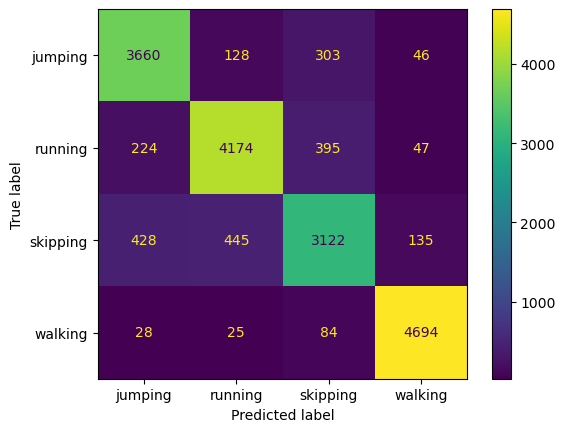

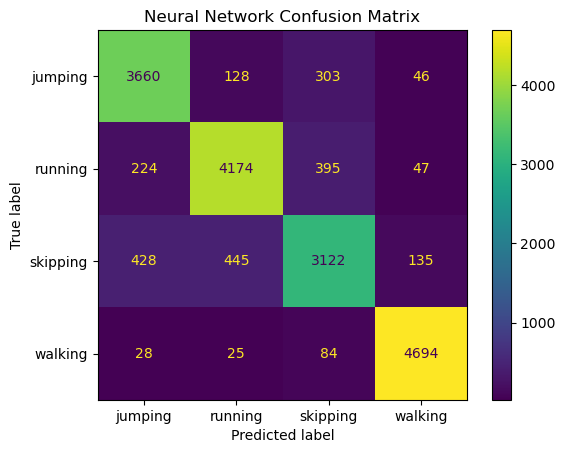

In [11]:
from sklearn.metrics import confusion_matrix, ConfusionMatrixDisplay

# Get predictions
predictions = model.predict(t_features_scaled)

# Convert probabilities to predicted class
predicted_classes = predictions.argmax(axis=1)

# Display confusion matrix
disp = ConfusionMatrixDisplay.from_predictions(
    t_activity,
    predicted_classes,
    display_labels=["jumping", "running", "skipping", "walking"],
    #normalize="true"
)

disp.plot()
plt.title("Neural Network Confusion Matrix")
plt.show()